# Pipeline NLLB + LoRA — Traducteur multilingue Français · Anglais · Éwé

**Projet de groupe — GR03** · Master 1 IA-BD EPL S2 (Informatique et Gestion de données)

| Membres du groupe GR03           |
|----------------------------------|
| AZIGLOSSOU Judith Gracia         |
| NAPO NISSAO Rafia                |
| WOGLO Koffi Boris Gilbride       |
| PIO Sikirou Afeez Prince Cyrille |
| KOMBATE Gountande                |

Sujet : *Traducteur Multilingue (Français, Anglais, Éwé) avec Reconnaissance Vocale* — proposé par Mme GBEDEVI.

---

Ce **notebook unique** regroupe tout le pipeline de traduction automatique demandé par le cahier des charges :

1. **Diagnostic GPU** — vérifier que CUDA est disponible avant l'entraînement.
2. **Vérification du corpus** — le dataset est construit en amont par `00_donnees.ipynb` ; on contrôle ici sa présence.
3. **Exploration du corpus** — volumes par direction, contrôle du biais religieux.
4. **Fine-tuning LoRA** de `facebook/nllb-200-distilled-600M` sur les 6 directions (fr↔en, fr↔ewe, en↔ewe).
5. **Suivi des pertes** (train / validation) et courbes.
6. **Évaluation finale BLEU / chrF** par direction.
7. **Comparaison base vs LoRA sur FLORES-200** pour mesurer l'apport réel du fine-tuning.
8. **Démo de traduction** sur l'adaptateur entraîné.

L'adaptateur LoRA final est sauvegardé dans `models/nllb-ewe-lora`, avec les rapports d'évaluation et le journal d'entraînement.


## 0. Mode d'emploi

1. Lancez ce notebook avec le kernel Python du projet : `.venv`.
2. Exécutez d'abord le diagnostic GPU. Si `torch.cuda.is_available()` vaut `False`, corrigez PyTorch CUDA avant de continuer.
3. Gardez `MODE = "smoke"` pour vérifier que tout marche rapidement (échantillon réduit, quelques minutes).
4. Passez à `MODE = "full"` pour le vrai fine-tuning sur l'ensemble du corpus.

La cellule de configuration ci-dessous fixe les chemins et les hyperparamètres. Le corpus d'entraînement est **augmenté par back-translation** (paires synthétiques en→éwé et fr→éwé à cible éwé humaine, généré par le notebook `02_backtranslation_nllb_lora.ipynb`) ; les ensembles `valid` et `test` restent les fichiers d'origine, ce qui garantit des scores comparables et **sans fuite**. Les hyperparamètres (2 époques, batch effectif de 64, longueurs de séquence de 128) s'adaptent automatiquement au `MODE` choisi.

Le notebook sauvegarde l'adaptateur LoRA dans `models/nllb-ewe-lora` et les rapports dans le même dossier.

In [1]:
from pathlib import Path
import os
import sys
import time
import json

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT / "src"))

DATA_DIR = PROJECT_ROOT / "data" / "processed" / "nllb"
TRAIN_CSV = DATA_DIR / "nllb_train.csv"
VALID_CSV = DATA_DIR / "nllb_valid.csv"
TEST_CSV = DATA_DIR / "nllb_test.csv"
SUMMARY_CSV = DATA_DIR / "nllb_summary.csv"

MODEL_NAME = "facebook/nllb-200-distilled-600M"
OUTPUT_DIR = PROJECT_ROOT / "models" / "nllb-ewe-lora"

MODE = "full"
REQUIRE_CUDA = True

IS_SMOKE = MODE == "smoke"
MAX_TRAIN_SAMPLES = 512 if IS_SMOKE else 200000
MAX_VALID_SAMPLES = 128 if IS_SMOKE else 6000
MAX_EVAL_PER_DIRECTION = 20 if IS_SMOKE else 200
EPOCHS = 0.05 if IS_SMOKE else 2.0
TRAIN_BATCH_SIZE = 32
EVAL_BATCH_SIZE = 32
GRADIENT_ACCUMULATION_STEPS = 2
MAX_SOURCE_LENGTH = 128
MAX_TARGET_LENGTH = 128
LEARNING_RATE = 2e-4

print("Projet:", PROJECT_ROOT)
print("Train:", TRAIN_CSV.name, "| échantillon:", MAX_TRAIN_SAMPLES, "| époques:", EPOCHS)
print("Batch effectif:", TRAIN_BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS)
print("Sortie LoRA:", OUTPUT_DIR)

Projet: D:\python\traducteur-fr-en-ewe
Train: nllb_train.csv | échantillon: 200000 | époques: 2.0
Batch effectif: 64
Sortie LoRA: D:\python\traducteur-fr-en-ewe\models\nllb-ewe-lora


## 1. Diagnostic GPU

Si Windows voit le GPU mais que cette cellule affiche `cuda_available = False`, le problème vient presque toujours d'une installation PyTorch CPU-only.

In [2]:
import torch

print("torch:", torch.__version__)
print("cuda_available:", torch.cuda.is_available())
print("torch_cuda_runtime:", torch.version.cuda)
print("device_count:", torch.cuda.device_count())
if torch.cuda.is_available():
    print("device_name:", torch.cuda.get_device_name(0))
    print("bf16_supported:", torch.cuda.is_bf16_supported())
    torch.set_float32_matmul_precision("high")
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
else:
    print("Commande conseillée :")
    print("python -m pip uninstall -y torch torchvision torchaudio")
    print("python -m pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu128")

if REQUIRE_CUDA and not torch.cuda.is_available():
    raise RuntimeError("CUDA indisponible dans cet environnement Python. Installez PyTorch CUDA avant l'entraînement.")

torch: 2.11.0+cu130
cuda_available: True
torch_cuda_runtime: 13.0
device_count: 1
device_name: NVIDIA GeForce RTX 5080 Laptop GPU
bf16_supported: True


## 2. Vérification du dataset

Le corpus est construit par le notebook **`00_donnees.ipynb`**, qui en est l'**unique source de vérité** (collecte, alignement, nettoyage, filtres anti-bruit, déduplication et découpage `train` / `valid` / `test`). Cette cellule se contente de vérifier que les fichiers attendus existent dans `data/processed/nllb/`. S'ils manquent, exécutez d'abord `00_donnees.ipynb`.

In [3]:
for path in [TRAIN_CSV, VALID_CSV, TEST_CSV, SUMMARY_CSV]:
    if not path.exists():
        raise FileNotFoundError(
            f"Fichier manquant : {path}. Exécutez d'abord le notebook 00_donnees.ipynb, "
            f"qui construit le dataset dans data/processed/nllb/."
        )
    print(path.relative_to(PROJECT_ROOT), "OK")

data\processed\nllb\nllb_train.csv OK
data\processed\nllb\nllb_valid.csv OK
data\processed\nllb\nllb_test.csv OK
data\processed\nllb\nllb_summary.csv OK


## 3. Exploration du corpus final

On vérifie ici les volumes, les directions et l'absence de corpus religieux dans le dataset d'entraînement.

,split,src_lang,tgt_lang,source,is_religious,rows
0,test,eng,ewe,flores:dev,False,24
1,test,eng,ewe,opus:bible_ee_en,True,312
2,test,eng,ewe,opus:nllb_ee_en,False,1801
3,test,eng,ewe,smol:smoldoc,False,36
4,test,eng,ewe,smol:smolsent,False,15
...,...,...,...,...,...,...
79,valid,fra,ewe,flores:dev,False,8
80,valid,fra,ewe,mafand:fr-ewe,False,28
81,valid,fra,ewe,opus:bible_ee_fr,True,60
82,valid,fra,ewe,opus:nllb_ee_fr,False,2287


Lignes religieuses: 38006


,split,src_lang,tgt_lang,rows
0,test,eng,ewe,2188
1,test,eng,fra,2431
2,test,ewe,eng,2188
3,test,ewe,fra,2411
4,test,fra,eng,2431
5,test,fra,ewe,2338
6,train,eng,ewe,104499
7,train,eng,fra,115223
8,train,ewe,eng,104499
9,train,ewe,fra,115184


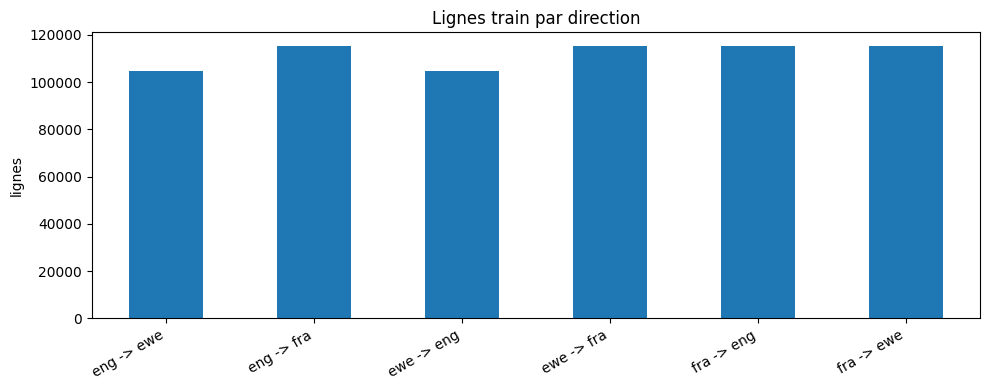

In [4]:
import pandas as pd

summary = pd.read_csv(SUMMARY_CSV)
display(summary)

religious_rows = int(summary.loc[summary["is_religious"] == True, "rows"].sum()) if (summary["is_religious"] == True).any() else 0
print("Lignes religieuses:", religious_rows)

direction_summary = summary.groupby(["split", "src_lang", "tgt_lang"], as_index=False)["rows"].sum()
display(direction_summary)

try:
    import matplotlib.pyplot as plt
    train_counts = direction_summary[direction_summary["split"] == "train"].copy()
    train_counts["direction"] = train_counts["src_lang"] + " -> " + train_counts["tgt_lang"]
    ax = train_counts.plot.bar(x="direction", y="rows", legend=False, figsize=(10, 4), title="Lignes train par direction")
    ax.set_xlabel("")
    ax.set_ylabel("lignes")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
except Exception as exc:
    print("Graphique non affiché :", exc)

## 4. Chargement des données pour l'entraînement

En mode `smoke`, on prend un petit échantillon. En mode `full`, on utilise tout le corpus.

In [5]:
def read_training_csv(path, max_samples=None):
    df = pd.read_csv(path)
    df["src_text"] = df["src_text"].fillna("").astype(str).str.strip()
    df["tgt_text"] = df["tgt_text"].fillna("").astype(str).str.strip()
    df = df[(df["src_text"].str.len() > 0) & (df["tgt_text"].str.len() > 0)]
    if max_samples:
        df = df.sample(n=min(max_samples, len(df)), random_state=42)
    return df.reset_index(drop=True)

train_df = read_training_csv(TRAIN_CSV, MAX_TRAIN_SAMPLES)
valid_df = read_training_csv(VALID_CSV, MAX_VALID_SAMPLES)

print("train:", len(train_df), "valid:", len(valid_df))
display(train_df[["src_lang", "tgt_lang", "src_lang_nllb", "tgt_lang_nllb", "src_text", "tgt_text", "source"]].head(8))

train: 200000 valid: 6000


,src_lang,tgt_lang,src_lang_nllb,tgt_lang_nllb,src_text,tgt_text,source
0,fra,eng,fra_Latn,eng_Latn,"Depuis l’indépendance de l’Inde il y 58 ans, d...","Since India gained independence 58 years ago, ...",opus:news_commentary_en_fr
1,ewe,fra,ewe_Latn,fra_Latn,Ele be woanya Mawu hafi ate ŋu alɔ̃e.,"Et pour l'aimer, il faut le connaître.",opus:nllb_ee_fr
2,fra,eng,fra_Latn,eng_Latn,Les déficits commerciaux reflètent les transac...,Trade deficits reflect transactions between pr...,opus:news_commentary_en_fr
3,eng,fra,eng_Latn,fra_Latn,Will it be necessary for us to buy a book for ...,Est-ce qu'il nous faudra acheter un livre pour...,opus:tatoeba_en_fr
4,fra,eng,fra_Latn,eng_Latn,"La réponse, c'est que tous les chefs d’entrepr...","And the answer is, every single Swedish busine...",opus:ted2020_en_fr
5,fra,eng,fra_Latn,eng_Latn,Elle a fait de la césarienne une pratique rout...,Surgeons could learn how to routinely and safe...,opus:ted2020_en_fr
6,eng,ewe,eng_Latn,ewe_Latn,"I will sing praise to your exalted name, O Mos...","Eye woadzi ha akafu wò ŋkɔ, Oo Dziƒoʋĩtɔ la,",opus:nllb_ee_en
7,ewe,eng,ewe_Latn,eng_Latn,Ame sia ame si xɔe se be Yesue nye Kristo la l...,Whoever believes that Jesus is the Christ is b...,opus:bible_ee_en


## 5. Modèle NLLB + LoRA

On charge `facebook/nllb-200-distilled-600M`, puis on ajoute des matrices LoRA sur **toutes les projections d'attention** (`q_proj`, `k_proj`, `v_proj`, `out_proj`) **et les couches feed-forward** (`fc1`, `fc2`). Cette capacité accrue est indispensable pour que le décodeur apprenne réellement à générer de l'éwé, langue peu dotée.

En mode `full`, on active le *gradient checkpointing* (et on désactive le cache) pour tenir dans la mémoire du GPU. On neutralise aussi `generation_config.max_length` afin de piloter la longueur uniquement via `max_new_tokens`.

In [6]:
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq
from transformers import Seq2SeqTrainer, Seq2SeqTrainingArguments
from peft import LoraConfig, TaskType, get_peft_model

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
base_model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)

base_model.generation_config.max_length = None

if MODE == "full":
    base_model.gradient_checkpointing_enable()
    base_model.config.use_cache = False

lora_config = LoraConfig(
    task_type=TaskType.SEQ_2_SEQ_LM,
    r=32,
    lora_alpha=64,
    lora_dropout=0.05,
    target_modules=["q_proj", "k_proj", "v_proj", "out_proj", "fc1", "fc2"],
)
model = get_peft_model(base_model, lora_config)
model.print_trainable_parameters()

D:\python\traducteur-fr-en-ewe\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 512/512 [00:00<00:00, 17349.90it/s]


trainable params: 17,301,504 || all params: 632,375,296 || trainable%: 2.7360


## 6. Tokenisation NLLB multidirectionnelle

Chaque ligne porte déjà `src_lang_nllb` et `tgt_lang_nllb`. Le tokenizer NLLB utilise ces codes pour injecter la bonne langue source et la bonne langue cible.

In [7]:
def preprocess(example):
    tokenizer.src_lang = example["src_lang_nllb"]
    tokenizer.tgt_lang = example["tgt_lang_nllb"]
    model_inputs = tokenizer(
        example["src_text"],
        max_length=MAX_SOURCE_LENGTH,
        truncation=True,
    )
    labels = tokenizer(
        text_target=example["tgt_text"],
        max_length=MAX_TARGET_LENGTH,
        truncation=True,
    )
    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

train_ds = Dataset.from_pandas(train_df, preserve_index=False).map(
    preprocess,
    remove_columns=train_df.columns.tolist(),
    desc="Tokenisation train",
)
valid_ds = Dataset.from_pandas(valid_df, preserve_index=False).map(
    preprocess,
    remove_columns=valid_df.columns.tolist(),
    desc="Tokenisation valid",
)

collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, model=model)
print(train_ds)
print(valid_ds)

Tokenisation valid: 100%|██████████| 6000/6000 [00:02<00:00, 2007.66 examples/s]

Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 200000
})
Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 6000
})


## 7. Entraînement avec suivi des pertes

Pendant l'entraînement, le Trainer affiche `loss`, `grad_norm`, `learning_rate` et `eval_loss`. L'évaluation et la sauvegarde sont alignées sur les mêmes pas, et `load_best_model_at_end` recharge le **meilleur checkpoint** (`eval_loss` minimale) plutôt que le dernier, ce qui protège d'un éventuel sur-apprentissage.

> Sous Windows + Jupyter, on garde `dataloader_num_workers = 0` : le multiprocessing « spawn » peut figer le démarrage de l'entraînement.

Après la cellule, on transforme l'historique en tableau et en courbes.

In [8]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

use_bf16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
use_fp16 = torch.cuda.is_available() and not use_bf16

eval_steps = 25 if MODE == "smoke" else 1000
save_steps = 50 if MODE == "smoke" else 1000
logging_steps = 5 if MODE == "smoke" else 50

DATALOADER_WORKERS = 0

training_args = Seq2SeqTrainingArguments(
    output_dir=str(OUTPUT_DIR),
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    num_train_epochs=EPOCHS,
    warmup_ratio=0.03,
    fp16=use_fp16,
    bf16=use_bf16,
    eval_strategy="steps",
    save_strategy="steps",
    eval_steps=eval_steps,
    save_steps=save_steps,
    logging_steps=logging_steps,
    save_total_limit=3,
    predict_with_generate=False,
    report_to="none",
    dataloader_num_workers=DATALOADER_WORKERS,
    dataloader_pin_memory=True,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=valid_ds,
    processing_class=tokenizer,
    data_collator=collator,
)

start = time.time()
train_result = trainer.train(resume_from_checkpoint=True)
elapsed = time.time() - start
trainer.save_model(str(OUTPUT_DIR))
tokenizer.save_pretrained(str(OUTPUT_DIR))

print("Temps d'entraînement (minutes) :", round(elapsed / 60, 2))
print("Adaptateur sauvegardé dans :", OUTPUT_DIR)

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Step,Training Loss,Validation Loss
3000,2.516360,1.127301
4000,2.399964,1.123895
5000,2.426850,1.118374
6000,2.445051,1.116638
6250,2.478343,1.116487


Temps d'entraînement (minutes) : 159.04
Adaptateur sauvegardé dans : D:\python\traducteur-fr-en-ewe\models\nllb-ewe-lora


## 8. Courbes et historique d'entraînement

Cette section affiche les métriques collectées pendant le fine-tuning.

,epoch,grad_norm,learning_rate,loss,step,eval_loss,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
113,1.744,0.487259,2.642692e-05,2.434729,5450,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
114,1.760,0.457670,2.477730e-05,2.450155,5500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
115,1.776,0.496988,2.312768e-05,2.369184,5550,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
116,1.792,0.501949,2.147806e-05,2.412480,5600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
117,1.808,0.443994,1.982844e-05,2.359179,5650,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
118,1.824,0.516598,1.817882e-05,2.393729,5700,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
119,1.840,0.515577,1.652920e-05,2.400374,5750,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
120,1.856,0.495714,1.487958e-05,2.398413,5800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
121,1.872,0.449159,1.322996e-05,2.428322,5850,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
122,1.888,0.533889,1.158034e-05,2.443911,5900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Historique sauvegardé : D:\python\traducteur-fr-en-ewe\models\nllb-ewe-lora\training_log.csv


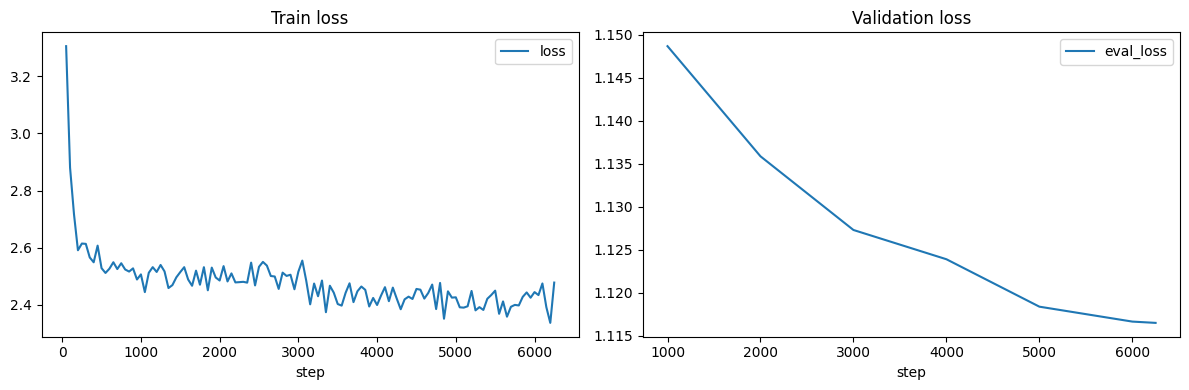

In [9]:
history = pd.DataFrame(trainer.state.log_history)
history_path = OUTPUT_DIR / "training_log.csv"
history.to_csv(history_path, index=False)
display(history.tail(20))
print("Historique sauvegardé :", history_path)

try:
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    if "loss" in history:
        history.dropna(subset=["loss"]).plot(x="step", y="loss", ax=axes[0], title="Train loss")
    if "eval_loss" in history:
        history.dropna(subset=["eval_loss"]).plot(x="step", y="eval_loss", ax=axes[1], title="Validation loss")
    plt.tight_layout()
except Exception as exc:
    print("Graphiques non affichés :", exc)

## 9. Évaluation finale BLEU / chrF

On génère des traductions sur `nllb_test.csv`, par direction, puis on calcule BLEU et chrF. Les métriques de génération sont plus lentes que `eval_loss`, donc on limite le nombre d'exemples par direction.

In [10]:
from sacrebleu import corpus_bleu, corpus_chrf

test_df = pd.read_csv(TEST_CSV)
model.eval()

def batched(values, size):
    for start_index in range(0, len(values), size):
        yield values[start_index:start_index + size]

def generate_for_group(group, batch_size=16):
    tokenizer.src_lang = group.iloc[0]["src_lang_nllb"]
    forced_bos_token_id = tokenizer.convert_tokens_to_ids(group.iloc[0]["tgt_lang_nllb"])
    predictions = []
    texts = group["src_text"].tolist()
    device = model.device
    with torch.no_grad():
        for batch in batched(texts, batch_size):
            encoded = tokenizer(
                batch,
                return_tensors="pt",
                padding=True,
                truncation=True,
                max_length=MAX_SOURCE_LENGTH,
            ).to(device)
            generated = model.generate(
                **encoded,
                forced_bos_token_id=forced_bos_token_id,
                max_new_tokens=MAX_TARGET_LENGTH,
                num_beams=4,
            )
            predictions.extend(tokenizer.batch_decode(generated, skip_special_tokens=True))
    return predictions

reports = []
examples = []
all_eval = {}
for (src_lang, tgt_lang), group in test_df.groupby(["src_lang", "tgt_lang"], sort=True):
    group = group.sample(n=min(MAX_EVAL_PER_DIRECTION, len(group)), random_state=42).reset_index(drop=True)
    predictions = generate_for_group(group, batch_size=16)
    references = group["tgt_text"].tolist()
    all_eval[(src_lang, tgt_lang)] = {
        "pred": predictions,
        "ref": references,
        "src": group["src_text"].tolist(),
    }
    reports.append({
        "src_lang": src_lang,
        "tgt_lang": tgt_lang,
        "rows": len(group),
        "bleu": round(float(corpus_bleu(predictions, [references]).score), 4),
        "chrf": round(float(corpus_chrf(predictions, [references]).score), 4),
    })
    for i in range(min(5, len(group))):
        examples.append({
            "src_lang": src_lang,
            "tgt_lang": tgt_lang,
            "src_text": group.loc[i, "src_text"],
            "reference": references[i],
            "prediction": predictions[i],
        })

report_df = pd.DataFrame(reports)
examples_df = pd.DataFrame(examples)
report_path = OUTPUT_DIR / "evaluation_report.csv"
examples_path = OUTPUT_DIR / "evaluation_examples.csv"
report_df.to_csv(report_path, index=False)
examples_df.to_csv(examples_path, index=False)

display(report_df)
display(examples_df)
print("Rapport:", report_path)
print("Exemples:", examples_path)

,src_lang,tgt_lang,rows,bleu,chrf
0,eng,ewe,200,29.6804,52.8811
1,eng,fra,200,39.7747,63.8509
2,ewe,eng,200,34.1444,53.3088
3,ewe,fra,200,35.9750,53.5064
4,fra,eng,200,43.2701,64.4103
5,fra,ewe,200,29.5228,51.4105


,src_lang,tgt_lang,src_text,reference,prediction
0,eng,ewe,Why I believe in the resurrection.,Nu ka tae míate ŋu axɔ tsitretsitsia dzi ase?,Nu ka tae mexɔ tsitretsitsia dzi se ɖo?
1,eng,ewe,The horns of the Altar,Vɔsamlekpui la ƒe dzowo.,Vɔsamlekpui la ƒe dzowo
2,eng,ewe,"The Bible says: ""The angel of Jehovah is campi...","Biblia gblɔ be: ""Yehowa ƒe dɔla ƒua asaɖa anyi...","Biblia gblɔ be: ""Yehowa ƒe dɔla ƒoa asaɖa anyi..."
3,eng,ewe,"Isaiah 55:10, the rain comes down and the snow...",Yes 55:10 ale si ko t. kple sno dzana tso dziƒo,Yes 55:10 tsidzadza kple kpetsi tso dziƒo
4,eng,ewe,2 He was present with God in the beginning.,2 Ame sia nɔ anyi kple Mawu le gɔmedzedzea me.,2 Ame ma nɔ anyi kple Mawu le gɔmedzedzea me.
5,eng,fra,"Similarly, the Institute for Supply Management...","De même, l’indice manufacturier de l’Institute...","De même, lInstitute for Supply Management Manu..."
6,eng,fra,"On the other hand, there's the liking processe...","D'autre part, ce sont les processus d'apprécia...","D'autre part, il y a les processus d'appréciat..."
7,eng,fra,I have to go to sleep.,Je dois aller dormir.,Je dois aller me coucher.
8,eng,fra,My father quit drinking.,Mon père a arrêté de boire.,Mon père a arrêté de boire.
9,eng,fra,"(Laughter) Everything is fine, as long as they...","(Rires) Tout va bien, du moment qu’elles trava...","(Rires) Tout va bien, tant qu'ils travaillent ..."


Rapport: D:\python\traducteur-fr-en-ewe\models\nllb-ewe-lora\evaluation_report.csv
Exemples: D:\python\traducteur-fr-en-ewe\models\nllb-ewe-lora\evaluation_examples.csv


## 9b. Graphes d'évaluation détaillés

Visualisation des scores de la section 9 (calculés sur le **test held-out**, jamais vu à l'entraînement) :

1. **BLEU et chrF par direction** — la qualité réelle de chaque sens de traduction.
2. **Taux d'off-target vers l'éwé** — part des prédictions censées être en éwé qui ne contiennent aucun caractère spécifique éwé (signal d'hallucination / sortie dans la mauvaise langue, surtout sur les directions peu dotées en↔ewe).
3. **Distribution des longueurs de prédiction** — détecte les sorties tronquées ou répétitives.

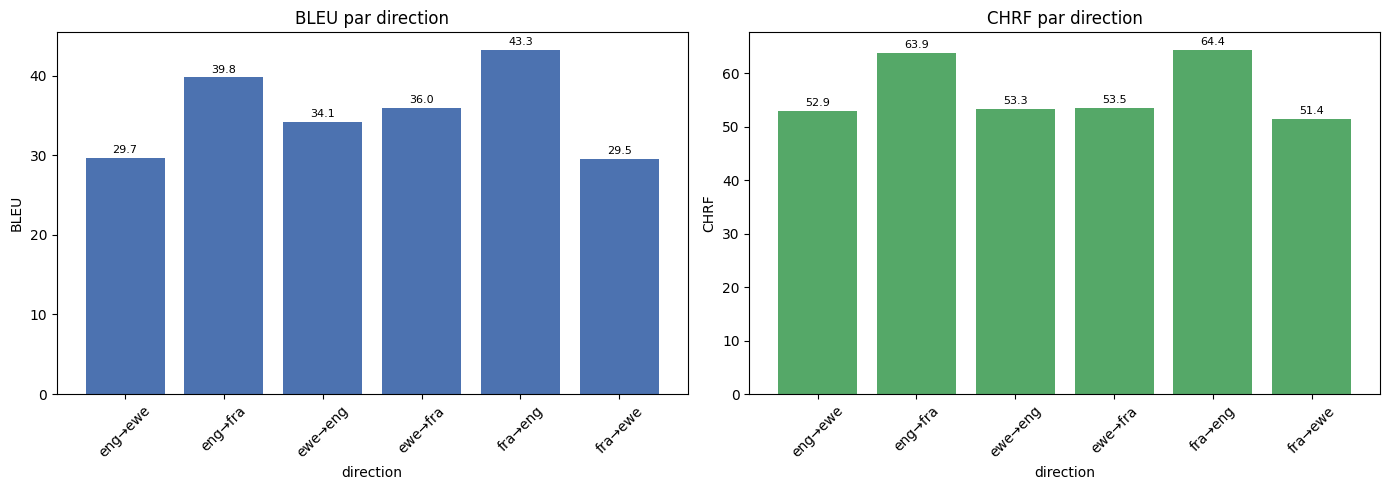

,direction,off_target_pct
0,eng→ewe,1.0
1,fra→ewe,0.5


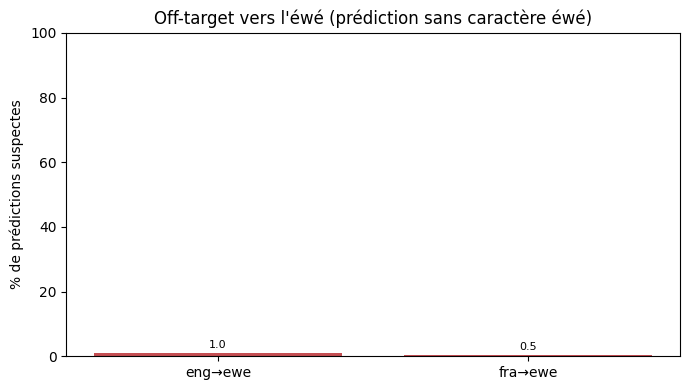

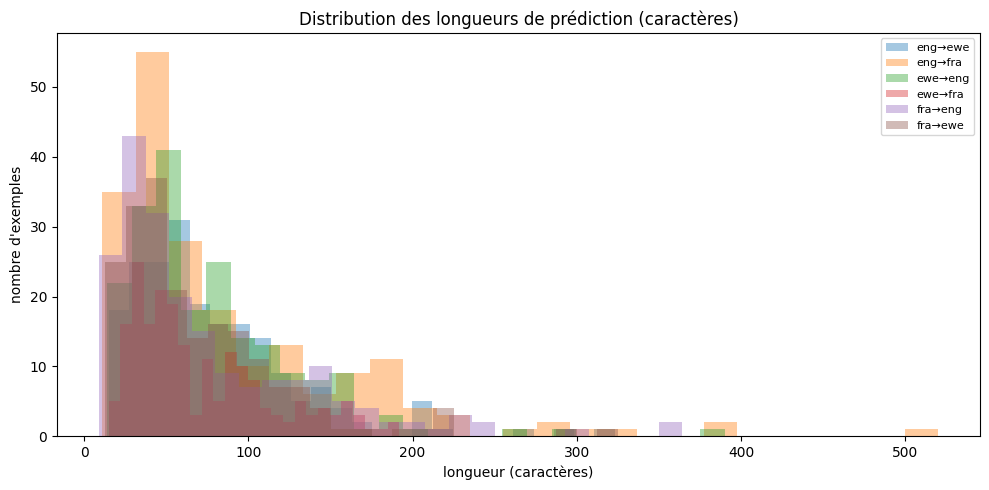

In [11]:
import matplotlib.pyplot as plt

plot_df = report_df.copy()
plot_df["direction"] = plot_df["src_lang"] + "→" + plot_df["tgt_lang"]
plot_df = plot_df.sort_values("direction").reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, color in zip(axes, ["bleu", "chrf"], ["#4C72B0", "#55A868"]):
    bars = ax.bar(plot_df["direction"], plot_df[metric], color=color)
    ax.set_title(f"{metric.upper()} par direction")
    ax.set_xlabel("direction")
    ax.set_ylabel(metric.upper())
    ax.tick_params(axis="x", rotation=45)
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)
plt.tight_layout()
plt.show()

EWE_CHARS = set("ɖƒŋɔɛɣʋãẽĩõũƉƑŊƆƐƔƲ")
off_rows = []
for (sl, tl), d in all_eval.items():
    if tl == "ewe":
        preds = d["pred"]
        off = sum(1 for p in preds if not any(c in EWE_CHARS for c in str(p))) / max(len(preds), 1)
        off_rows.append({"direction": f"{sl}→{tl}", "off_target_pct": round(100 * off, 1)})
if off_rows:
    off_df = pd.DataFrame(off_rows).sort_values("direction").reset_index(drop=True)
    display(off_df)
    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.bar(off_df["direction"], off_df["off_target_pct"], color="#C44E52")
    ax.set_title("Off-target vers l'éwé (prédiction sans caractère éwé)")
    ax.set_ylabel("% de prédictions suspectes")
    ax.set_ylim(0, 100)
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)
    plt.tight_layout()
    plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
for (sl, tl), d in sorted(all_eval.items()):
    lengths = [len(str(p)) for p in d["pred"]]
    ax.hist(lengths, bins=25, alpha=0.4, label=f"{sl}→{tl}")
ax.set_title("Distribution des longueurs de prédiction (caractères)")
ax.set_xlabel("longueur (caractères)")
ax.set_ylabel("nombre d'exemples")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 10. Évaluation FLORES-200 : modèle de base vs adaptateur LoRA

FLORES-200 est le jeu de référence multilingue de Meta : ses phrases sont alignées dans les trois langues, ce qui rend les scores **honnêtes et comparables à l'état de l'art**, y compris pour les directions en↔éwé. On utilise le découpage `devtest`, **jamais vu à l'entraînement** (seul `dev` a pu alimenter le corpus, cf. notebook des données).

L'adaptateur LoRA est déjà enroulé autour du modèle de base, en mémoire. On évalue donc les deux versions **sans recharger le modèle** : la version « base » s'obtient en désactivant l'adaptateur avec `model.disable_adapter()`, la version « LoRA » en le laissant actif. On mesure BLEU et chrF sur les six directions.

In [12]:
from datasets import load_dataset

FLORES_LANGS = {"eng": "eng_Latn", "fra": "fra_Latn", "ewe": "ewe_Latn"}
flores_split = "devtest"

flores_texts = {}
try:
    per_id = {}
    for short, lang_code in FLORES_LANGS.items():
        ds = load_dataset("openlanguagedata/flores_plus", lang_code, split=flores_split)
        per_id[short] = {str(r["id"]): r["text"] for r in ds}
    common = sorted(set.intersection(*[set(d) for d in per_id.values()]))
    flores_texts = {short: [per_id[short][i] for i in common] for short in FLORES_LANGS}
except Exception as exc:
    print(f"FLORES+ indisponible ({type(exc).__name__}), repli sur facebook/flores 'all'.")
    ds = load_dataset("facebook/flores", "all", split=flores_split, trust_remote_code=True)
    flores_texts = {short: [r[f"sentence_{lang_code}"] for r in ds] for short, lang_code in FLORES_LANGS.items()}

n_flores = len(next(iter(flores_texts.values())))
flores_rows = []
for s in FLORES_LANGS:
    for t in FLORES_LANGS:
        if s == t:
            continue
        for i in range(n_flores):
            flores_rows.append({"src_lang": s, "tgt_lang": t,
                                "src_text": flores_texts[s][i], "tgt_text": flores_texts[t][i]})
flores_df = pd.DataFrame(flores_rows)
print(f"FLORES {flores_split}: {n_flores} phrases par langue, {len(flores_df)} paires sur 6 directions.")

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'facebook/flores' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


FLORES+ indisponible (DatasetNotFoundError), repli sur facebook/flores 'all'.
FLORES devtest: 1012 phrases par langue, 6072 paires sur 6 directions.


On génère les traductions avec puis sans adaptateur pour chaque direction, sur un échantillon par direction (`MAX_EVAL_PER_DIRECTION`). La colonne `d_bleu` (resp. `d_chrf`) donne directement l'apport de l'adaptateur : positif = le fine-tuning améliore la traduction.

In [13]:
from sacrebleu import corpus_bleu, corpus_chrf
from contextlib import nullcontext

model.eval()
flores_use_bf16 = (model.device.type == "cuda") and torch.cuda.is_bf16_supported()

@torch.no_grad()
def flores_generate(group, use_adapter):
    tokenizer.src_lang = FLORES_LANGS[group.iloc[0]["src_lang"]]
    forced_bos_token_id = tokenizer.convert_tokens_to_ids(FLORES_LANGS[group.iloc[0]["tgt_lang"]])
    adapter_ctx = nullcontext() if use_adapter else model.disable_adapter()
    autocast_ctx = torch.autocast("cuda", dtype=torch.bfloat16) if flores_use_bf16 else nullcontext()
    preds = []
    with adapter_ctx:
        for batch in batched([str(x) for x in group["src_text"].tolist()], EVAL_BATCH_SIZE):
            encoded = tokenizer(batch, return_tensors="pt", padding=True,
                                truncation=True, max_length=MAX_SOURCE_LENGTH).to(model.device)
            with autocast_ctx:
                generated = model.generate(**encoded, forced_bos_token_id=forced_bos_token_id,
                                           max_new_tokens=MAX_TARGET_LENGTH, num_beams=4)
            preds.extend(tokenizer.batch_decode(generated, skip_special_tokens=True))
    return preds

flores_reports = []
flores_examples = []
for (src_lang, tgt_lang), group in flores_df.groupby(["src_lang", "tgt_lang"], sort=True):
    group = group.sample(n=min(MAX_EVAL_PER_DIRECTION, len(group)), random_state=42).reset_index(drop=True)
    refs = group["tgt_text"].astype(str).tolist()
    base_preds = flores_generate(group, use_adapter=False)
    lora_preds = flores_generate(group, use_adapter=True)
    base_bleu = float(corpus_bleu(base_preds, [refs]).score)
    lora_bleu = float(corpus_bleu(lora_preds, [refs]).score)
    base_chrf = float(corpus_chrf(base_preds, [refs]).score)
    lora_chrf = float(corpus_chrf(lora_preds, [refs]).score)
    flores_reports.append({
        "direction": f"{src_lang}->{tgt_lang}", "rows": len(group),
        "base_bleu": round(base_bleu, 2), "lora_bleu": round(lora_bleu, 2), "d_bleu": round(lora_bleu - base_bleu, 2),
        "base_chrf": round(base_chrf, 2), "lora_chrf": round(lora_chrf, 2), "d_chrf": round(lora_chrf - base_chrf, 2),
    })
    for i in range(min(4, len(group))):
        flores_examples.append({
            "direction": f"{src_lang}->{tgt_lang}", "src_text": group.loc[i, "src_text"],
            "reference": refs[i], "base": base_preds[i], "lora": lora_preds[i],
        })

flores_report_df = pd.DataFrame(flores_reports)
moyenne = {
    "direction": "MOYENNE", "rows": int(flores_report_df["rows"].sum()),
    "base_bleu": round(flores_report_df["base_bleu"].mean(), 2),
    "lora_bleu": round(flores_report_df["lora_bleu"].mean(), 2),
    "d_bleu": round(flores_report_df["d_bleu"].mean(), 2),
    "base_chrf": round(flores_report_df["base_chrf"].mean(), 2),
    "lora_chrf": round(flores_report_df["lora_chrf"].mean(), 2),
    "d_chrf": round(flores_report_df["d_chrf"].mean(), 2),
}
flores_report_df = pd.concat([flores_report_df, pd.DataFrame([moyenne])], ignore_index=True)
flores_examples_df = pd.DataFrame(flores_examples)
flores_report_path = OUTPUT_DIR / "flores_base_vs_lora.csv"
flores_examples_path = OUTPUT_DIR / "flores_base_vs_lora_examples.csv"
flores_report_df.to_csv(flores_report_path, index=False, encoding="utf-8")
flores_examples_df.to_csv(flores_examples_path, index=False, encoding="utf-8")

display(flores_report_df)
display(flores_examples_df)
print("Rapport:", flores_report_path)
print("Exemples:", flores_examples_path)

,direction,rows,base_bleu,lora_bleu,d_bleu,base_chrf,lora_chrf,d_chrf
0,eng->ewe,200,12.65,13.34,0.69,38.42,39.44,1.03
1,eng->fra,200,45.89,47.96,2.06,68.18,69.88,1.70
2,ewe->eng,200,15.16,16.05,0.89,37.94,39.86,1.92
3,ewe->fra,200,11.45,13.62,2.17,34.36,37.82,3.47
4,fra->eng,200,42.76,43.49,0.73,66.12,67.12,0.99
5,fra->ewe,200,9.86,10.76,0.90,35.61,36.34,0.73
6,MOYENNE,1200,22.96,24.20,1.24,46.77,48.41,1.64


,direction,src_text,reference,base,lora
0,eng->ewe,Vatican City's population is around 800. It is...,Vatika dukͻa ƒe agbͻsͻsͻ nye 800. Eyae nye duk...,"Vatican City me tɔwo le abe 800 ene, eya ta ey...",Vatican City ƒe amewo le abe 800 ene. Eyae nye...
1,eng->ewe,All citizens of Vatican City are Roman Catholic.,Vatika vidzidziwo katã nye Roman Katolikotͻwo.,Roma Katolikowoe nye Vatikan-dua me nɔlawo katã.,Dukɔ sia me tɔwo katã nye Roma Katolikotɔwo.
2,eng->ewe,It has a notably wide variety of plant communi...,Ati ƒomevi geɖewo le eme kuɖe eƒe yame ƒe nɔnɔ...,"Atikeƒomewo ƒe agbɔsɔsɔme sɔ gbɔ ale gbegbe, e...","Atikeƒomewo ƒe agbɔsɔsɔme le etɔxɛ, le eƒe nuk..."
3,eng->ewe,The Amazon River is the second longest and the...,Amazontͻsisia nye tͻ si ƒe dzidzime nye evelia...,Amazon-tɔsisiae nye tɔsisi didi evelia kple gã...,Amazon Tɔsisiae nye tɔsisi didi evelia kple gã...
4,eng->fra,Vatican City's population is around 800. It is...,Le Vatican compte environ 800 habitants. C'est...,La population de la Cité du Vatican est d'envi...,La population de la Cité du Vatican est d'envi...
5,eng->fra,All citizens of Vatican City are Roman Catholic.,Les citoyens de la Cité du Vatican sont tous c...,Tous les citoyens du Vatican sont catholiques.,Tous les citoyens de Vatican sont catholiques ...
6,eng->fra,It has a notably wide variety of plant communi...,Le pays possède une grande variété de communau...,Elle possède notamment une grande variété de c...,Elle possède notamment une grande variété de c...
7,eng->fra,The Amazon River is the second longest and the...,Le fleuve Amazone est le deuxième plus long et...,L'Amazonie est le deuxième fleuve le plus long...,L'Amazonie est le deuxième fleuve le plus long...
8,ewe->eng,Vatika dukͻa ƒe agbͻsͻsͻ nye 800. Eyae nye duk...,Vatican City's population is around 800. It is...,The Vatican City has a population of 800. It i...,The Vatican City has a population of 800. It i...
9,ewe->eng,Vatika vidzidziwo katã nye Roman Katolikotͻwo.,All citizens of Vatican City are Roman Catholic.,All Vatican citizens were Roman Catholics by b...,They were all born Roman Catholics.


Rapport: D:\python\traducteur-fr-en-ewe\models\nllb-ewe-lora\flores_base_vs_lora.csv
Exemples: D:\python\traducteur-fr-en-ewe\models\nllb-ewe-lora\flores_base_vs_lora_examples.csv


### Comparaison visuelle base vs LoRA

Pour chaque direction, le score du modèle de base et celui de l'adaptateur LoRA sont placés côte à côte (la ligne `MOYENNE` est exclue des barres). L'écart visible mesure l'apport du fine-tuning, attendu surtout sur les directions vers l'éwé.

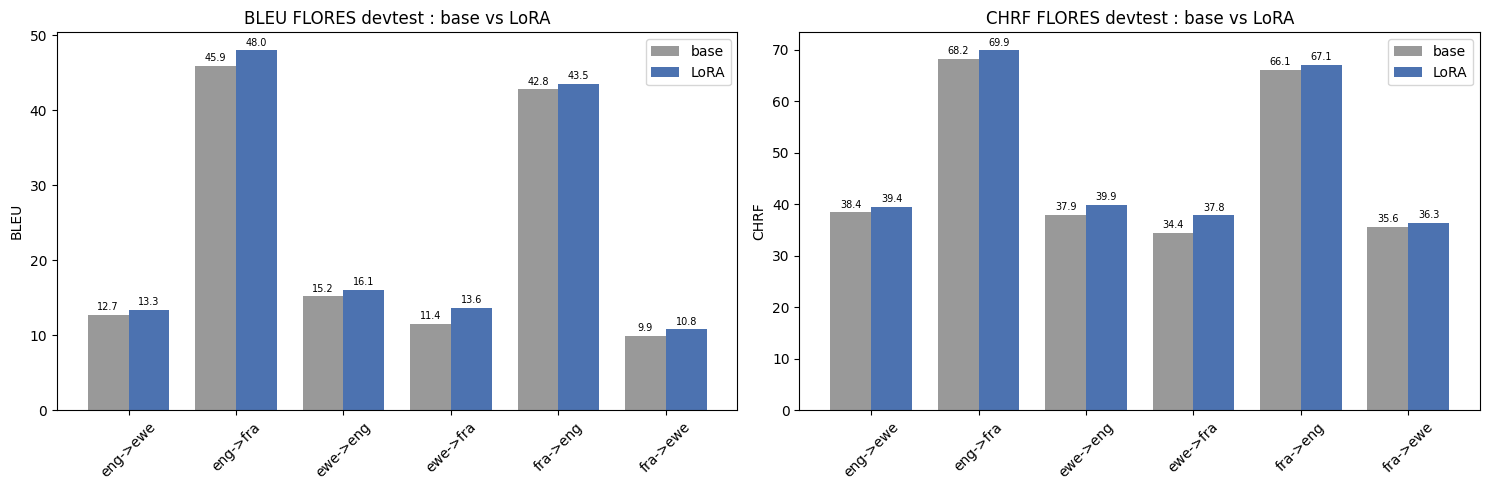

In [14]:
plot_flores = flores_report_df[flores_report_df["direction"] != "MOYENNE"].copy().reset_index(drop=True)
positions = range(len(plot_flores))
width = 0.38

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric in zip(axes, ["bleu", "chrf"]):
    base_bars = ax.bar([p - width / 2 for p in positions], plot_flores[f"base_{metric}"], width, label="base", color="#999999")
    lora_bars = ax.bar([p + width / 2 for p in positions], plot_flores[f"lora_{metric}"], width, label="LoRA", color="#4C72B0")
    ax.set_title(f"{metric.upper()} FLORES devtest : base vs LoRA")
    ax.set_xticks(list(positions))
    ax.set_xticklabels(plot_flores["direction"], rotation=45)
    ax.set_ylabel(metric.upper())
    ax.bar_label(base_bars, fmt="%.1f", padding=2, fontsize=7)
    ax.bar_label(lora_bars, fmt="%.1f", padding=2, fontsize=7)
    ax.legend()
plt.tight_layout()
plt.show()

## 11. Démo de traduction

Cette cellule permet de tester rapidement l'adaptateur LoRA chargé en mémoire.

In [15]:
LANG_TO_NLLB = {"fra": "fra_Latn", "eng": "eng_Latn", "ewe": "ewe_Latn"}

def translate_text(text, source_lang="fra", target_lang="ewe", max_new_tokens=128):
    model.eval()
    tokenizer.src_lang = LANG_TO_NLLB[source_lang]
    forced_bos_token_id = tokenizer.convert_tokens_to_ids(LANG_TO_NLLB[target_lang])
    encoded = tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_SOURCE_LENGTH).to(model.device)
    with torch.no_grad():
        generated = model.generate(
            **encoded,
            forced_bos_token_id=forced_bos_token_id,
            max_new_tokens=max_new_tokens,
            num_beams=4,
        )
    return tokenizer.batch_decode(generated, skip_special_tokens=True)[0]

tests = [
    ("Bonjour, comment vas-tu ?", "fra", "ewe"),
    ("I am going to school tomorrow.", "eng", "ewe"),
    ("Je vais bien.", "fra", "eng"),
]

for text, src, tgt in tests:
    print(f"{src} -> {tgt}: {text}")
    print("=>", translate_text(text, src, tgt))
    print()

fra -> ewe: Bonjour, comment vas-tu ?
=> Alo, aleke nèsena le ɖokuiwò me?

eng -> ewe: I am going to school tomorrow.
=> Etsɔ la meyina suku.

fra -> eng: Je vais bien.
=> I'm fine.



In [16]:
trainer.save_model(str(OUTPUT_DIR))
tokenizer.save_pretrained(str(OUTPUT_DIR))
print("Adaptateur et tokenizer sauvegardés dans", OUTPUT_DIR)

Adaptateur et tokenizer sauvegardés dans D:\python\traducteur-fr-en-ewe\models\nllb-ewe-lora
